In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
BASE = r"C:\project 1"      # change this if you renamed the folder
os.chdir(BASE)
print(os.getcwd())
print(os.listdir("."))

C:\project 1
['data', 'note book', 'README', 'reports', 'sql', 'visualizations']


In [2]:
df = pd.read_csv("data/superstore.csv", encoding="latin1")

df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.shape

(9994, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [5]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [6]:
print(df.isnull().sum())
print(df.duplicated().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
0


In [7]:
# Exploratory Data Analysis (EDA)
#1 Which products generate the highest revenue?
top_products = df.groupby('Product Name',)['Sales'].sum()

top_products = top_products.sort_values(ascending=False).head(10)

top_products


Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

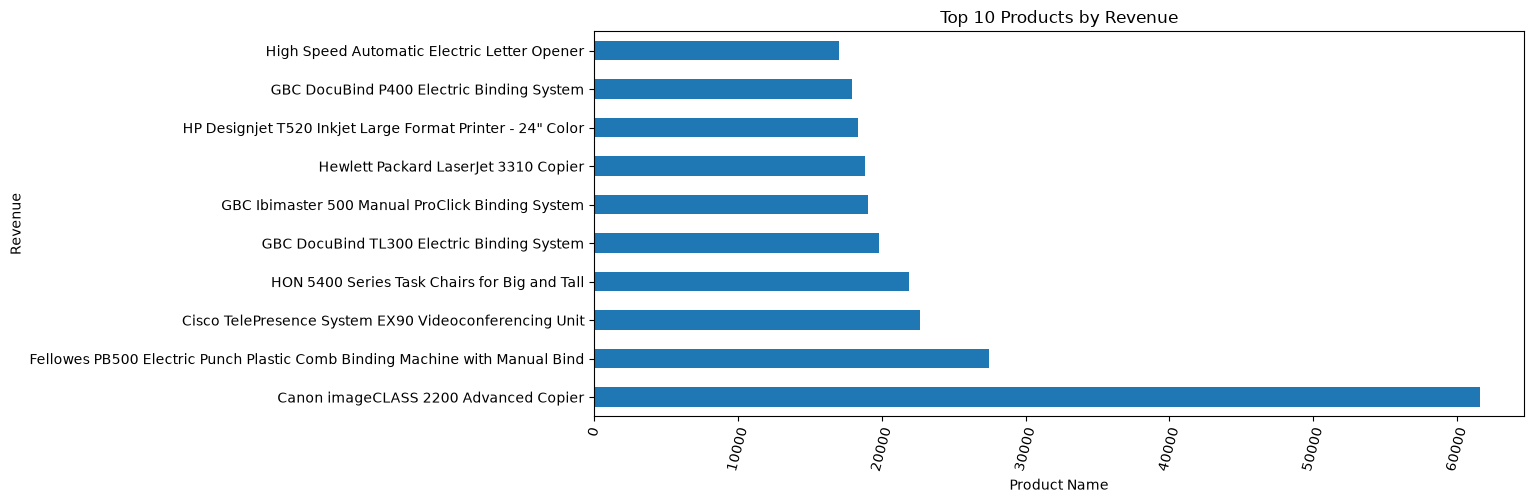

In [8]:
top_products.plot(kind='barh', figsize=(12,5))

plt.title('Top 10 Products by Revenue')
plt.xlabel('Product Name')
plt.ylabel('Revenue')
plt.xticks(rotation=75)
plt.savefig("visualizations/top_products.png", dpi=150, bbox_inches="tight")
plt.show()

Top 3 months by sales:
Nov    352461.07
Dec    325293.50
Sep    307649.95
Name: Sales, dtype: float64


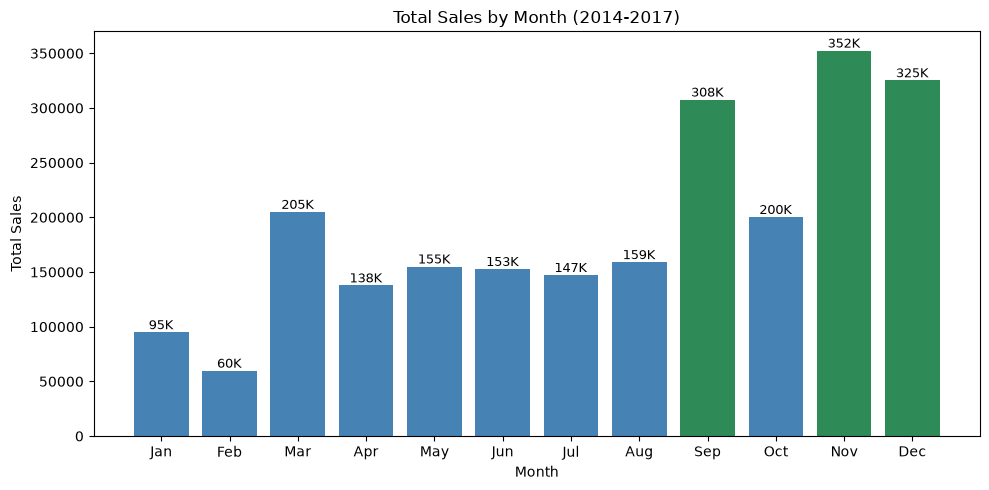

In [9]:
# Q2: Which months have the highest sales?
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Month'] = df['Order Date'].dt.month

month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly_sales = df.groupby('Month')['Sales'].sum()
monthly_sales.index = month_names

# Answer in numbers
print("Top 3 months by sales:")
print(monthly_sales.sort_values(ascending=False).head(3).round(2))

# Highlight the top 3 months
top3 = monthly_sales.nlargest(3).index
colors = ['seagreen' if m in top3 else 'steelblue' for m in monthly_sales.index]

plt.figure(figsize=(10,5))
bars = plt.bar(monthly_sales.index, monthly_sales.values, color=colors)

# Value labels on top of bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f"{bar.get_height()/1000:.0f}K", ha='center', va='bottom', fontsize=9)

plt.title('Total Sales by Month (2014-2017)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.savefig('visualizations/monthly_sales.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
#3 Which regions perform best?
region_sales = df.groupby('Region')['Sales'].sum()

region_sales = region_sales.sort_values(ascending=False)

region_sales


Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

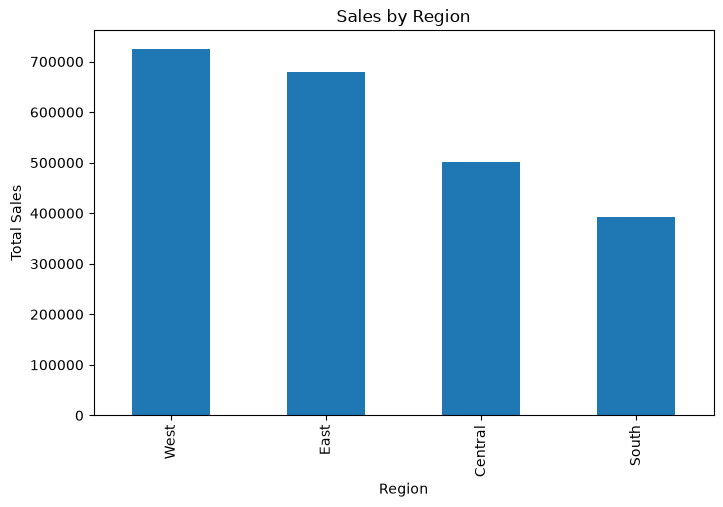

In [11]:
region_sales.plot(kind='bar', figsize=(8,5))

plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.savefig('visualizations/region_performance.png', dpi=150, bbox_inches='tight')
plt.show()

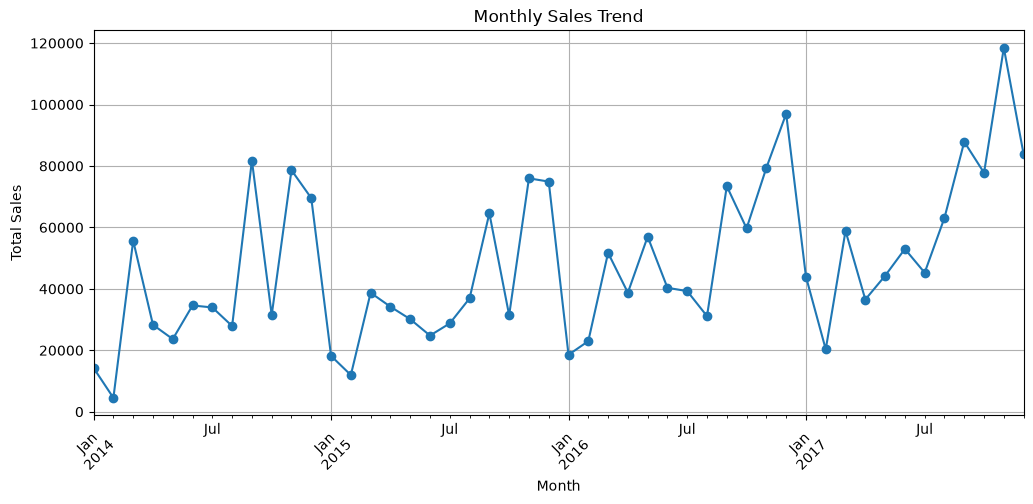

In [12]:
# Q4: Sales trend over time
monthly_trend = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()

monthly_trend.plot(figsize=(12,5), marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid()
plt.savefig('visualizations/sales_trend.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()

print(f"Total Sales:  ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {total_profit / total_sales * 100:.2f}%")

Total Sales:  $2,297,200.86
Total Profit: $286,397.02
Profit Margin: 12.47%


In [14]:
import sqlite3

df_sql = df.copy()
df_sql['Order Date'] = df_sql['Order Date'].dt.strftime('%Y-%m-%d')

conn = sqlite3.connect('data/ecommerce.db')      # creates the file in your data folder
df_sql.to_sql('orders', conn, if_exists='replace', index=False)

pd.read_sql("SELECT COUNT(*) AS total_rows FROM orders", conn)

,total_rows
0,9994


In [15]:
# Q1: Top 10 products by revenue
q1 = """
SELECT "Product Name", ROUND(SUM(Sales), 2) AS revenue
FROM orders
GROUP BY "Product Name"
ORDER BY revenue DESC
LIMIT 10;
"""
pd.read_sql(q1, conn)

,Product Name,revenue
0,Canon imageCLASS 2200 Advanced Copier,61599.82
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
2,Cisco TelePresence System EX90 Videoconferenci...,22638.48
3,HON 5400 Series Task Chairs for Big and Tall,21870.58
4,GBC DocuBind TL300 Electric Binding System,19823.48
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.50
6,Hewlett Packard LaserJet 3310 Copier,18839.69
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.90
8,GBC DocuBind P400 Electric Binding System,17965.07
9,High Speed Automatic Electric Letter Opener,17030.31


In [16]:
# Q2: Sales by month (all years combined)
q2 = """
SELECT strftime('%m', "Order Date") AS month, ROUND(SUM(Sales), 2) AS sales
FROM orders
GROUP BY month
ORDER BY sales DESC;
"""
pd.read_sql(q2, conn)

,month,sales
0,11,352461.07
1,12,325293.50
2,09,307649.95
3,03,205005.49
4,10,200322.98
5,08,159044.06
6,05,155028.81
7,06,152718.68
8,07,147238.10
9,04,137762.13


In [17]:
# Q3: Region performance
q3 = """
SELECT Region,
       ROUND(SUM(Sales), 2) AS sales,
       ROUND(SUM(Profit), 2) AS profit,
       ROUND(SUM(Profit) / SUM(Sales) * 100, 2) AS margin_pct
FROM orders
GROUP BY Region
ORDER BY sales DESC;
"""
pd.read_sql(q3, conn)

,Region,sales,profit,margin_pct
0,West,725457.82,108418.45,14.94
1,East,678781.24,91522.78,13.48
2,Central,501239.89,39706.36,7.92
3,South,391721.91,46749.43,11.93


In [18]:
# Q4: Monthly sales and profit trend
q4 = """
SELECT strftime('%Y-%m', "Order Date") AS year_month,
       ROUND(SUM(Sales), 2) AS sales,
       ROUND(SUM(Profit), 2) AS profit
FROM orders
GROUP BY year_month
ORDER BY year_month;
"""
pd.read_sql(q4, conn)

,year_month,sales,profit
0,2014-01,14236.90,2450.19
1,2014-02,4519.89,862.31
2,2014-03,55691.01,498.73
3,2014-04,28295.35,3488.84
4,2014-05,23648.29,2738.71
5,2014-06,34595.13,4976.52
6,2014-07,33946.39,-841.48
7,2014-08,27909.47,5318.10
8,2014-09,81777.35,8328.10
9,2014-10,31453.39,3448.26


In [19]:
with open('sql/queries.sql', 'w') as f:
    f.write("-- Q1: Top 10 products by revenue" + q1 + "\n")
    f.write("-- Q2: Sales by month" + q2 + "\n")
    f.write("-- Q3: Region performance" + q3 + "\n")
    f.write("-- Q4: Monthly sales and profit trend" + q4 + "\n")

    

In [20]:
conn.close()

Discount-Profit correlation: -0.219
Discount Band
0%         66.90
1-20%      26.50
21-40%    -77.86
>40%     -106.71
Name: Profit, dtype: float64


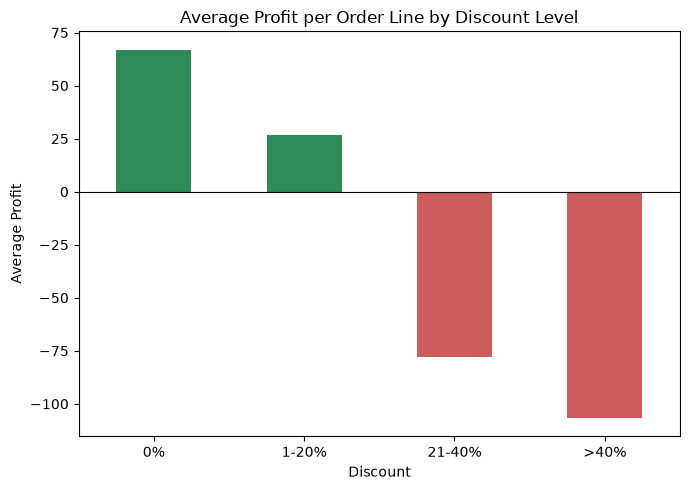

In [21]:
print("Discount-Profit correlation:", round(df['Discount'].corr(df['Profit']), 3))

df['Discount Band'] = pd.cut(df['Discount'], [-0.01, 0, 0.2, 0.4, 1],
                             labels=['0%', '1-20%', '21-40%', '>40%'])
disc = df.groupby('Discount Band', observed=True)['Profit'].mean()
print(disc.round(2))

disc.plot(kind='bar', color=['seagreen','seagreen','indianred','indianred'], figsize=(7,5))
plt.title('Average Profit per Order Line by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.xticks(rotation=0)
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('visualizations/discount_vs_profit.png', dpi=150, bbox_inches='tight')
plt.show()

                                  Sales    Profit
Category        Sub-Category                     
Furniture       Tables        206965.53 -17725.48
                Bookcases     114880.00  -3472.56
Office Supplies Supplies       46673.54  -1189.10
                Fasteners       3024.28    949.52
Technology      Machines      189238.63   3384.76
Office Supplies Labels         12486.31   5546.25
                Art            27118.79   6527.79
                Envelopes      16476.40   6964.18
Furniture       Furnishings    91705.16  13059.14
Office Supplies Appliances    107532.16  18138.01
                Storage       223843.61  21278.83
Furniture       Chairs        328449.10  26590.17
Office Supplies Binders       203412.73  30221.76
                Paper          78479.21  34053.57
Technology      Accessories   167380.32  41936.64
                Phones        330007.05  44515.73
                Copiers       149528.03  55617.82


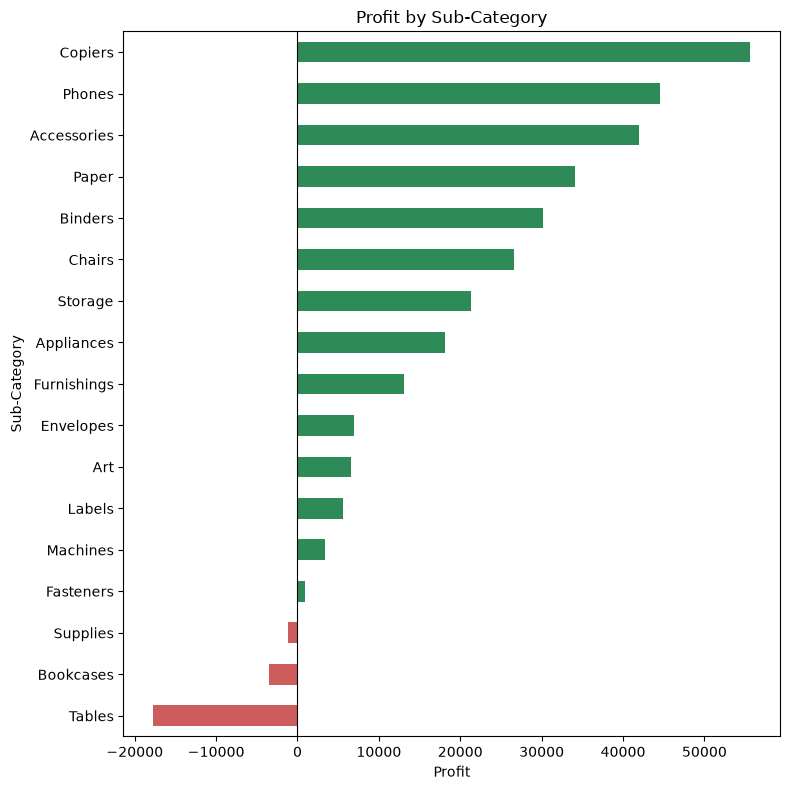

In [22]:
sub = df.groupby(['Category','Sub-Category'])[['Sales','Profit']].sum().sort_values('Profit')
print(sub.round(2))

sub_profit = sub['Profit'].droplevel(0)
colors = ['indianred' if p < 0 else 'seagreen' for p in sub_profit]

sub_profit.plot(kind='barh', figsize=(8,8), color=colors)
plt.title('Profit by Sub-Category')
plt.xlabel('Profit')
plt.ylabel('Sub-Category')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('visualizations/profit_by_subcategory.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
loss = df.groupby('Product Name')['Profit'].sum().sort_values().head(10)
print(loss.round(2))

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.97
Lexmark MX611dhe Monochrome Laser Printer                           -4589.97
Cubify CubeX 3D Printer Triple Head Print                           -3839.99
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.12
Bush Advantage Collection Racetrack Conference Table                -1934.40
GBC DocuBind P400 Electric Binding System                           -1878.17
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.08
Martin Yale Chadless Opener Electric Letter Opener                  -1299.18
Balt Solid Wood Round Tables                                        -1201.06
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.44
Name: Profit, dtype: float64
